<a href="https://colab.research.google.com/github/contreras-juan/procesamiento_lenguaje_natural/blob/main/Cuadernos/11_Embeddings_Redes_Neuronales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1 style="color: #FECB05; text-align: center;">Embeddings de palabras con redes neuronales</h1>

<h2 style="color: #007ACC;">Autores</h2>

- [Juan Felipe Contreras Alcívar](https://www.linkedin.com/in/juanf-contreras/)

---

<h2 style="color: #007ACC;">Tabla de contenido</h2>

- [<span style="color: #005C99;">Introducción</span>](#introduccion)
- [<span style="color: #005C99;">De vectores one-hot a representaciones densas</span>](#de-vectores-one-hot-a-representaciones-densas)
- [<span style="color: #005C99;">Datos: reseñas de Amazon en español</span>](#datos-resenas-de-amazon-en-espanol)
- [<span style="color: #005C99;">Vectorización de texto con Keras</span>](#vectorizacion-de-texto-con-keras)
- [<span style="color: #005C99;">La capa Embedding</span>](#la-capa-embedding)
- [<span style="color: #005C99;">Un clasificador con embeddings</span>](#un-clasificador-con-embeddings)
- [<span style="color: #005C99;">Visualización de los embeddings aprendidos</span>](#visualizacion-de-los-embeddings-aprendidos)
- [<span style="color: #005C99;">Embeddings en dos dimensiones</span>](#embeddings-en-dos-dimensiones)
- [<span style="color: #005C99;">Referencias</span>](#referencias)

---

<h2 style="color: #007ACC;">Instalación de librerías</h2>

Ejecuta esta celda si trabajas en Google Colab o en un entorno nuevo.

In [1]:
# Instalación de librerías necesarias para esta sesión
# (útil en Google Colab o en un entorno nuevo)
%pip install -q numpy pandas matplotlib scikit-learn tensorflow datasets

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  # oculta mensajes informativos de TensorFlow

import re
import string
import time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
keras.utils.set_random_seed(SEED)  # fija las semillas de Python, NumPy y TensorFlow

<a id="introduccion"></a>
<h2 style="color: #007ACC;">Introducción</h2>

En los módulos 1 y 2 cada palabra era un **símbolo**: una columna en una bolsa de palabras o una fila en una tabla de conteos. Esa representación tiene dos problemas que ya encontramos varias veces:

1. **Dimensión enorme y dispersión:** cada palabra del vocabulario es una dimensión, y casi todas valen cero.
2. **Ninguna noción de similitud:** *excelente* y *buenísimo* son tan distintas para el modelo como *excelente* y *tornillo*. Lo que el modelo aprende sobre una palabra no se transfiere a sus sinónimos.

Los **embeddings** representan cada palabra con un **vector denso** de pocas dimensiones (típicamente 50–300) cuyos valores se **aprenden** de los datos. Palabras que cumplen funciones parecidas en la tarea terminan con vectores parecidos. En el cuaderno 05 construimos vectores densos con PPMI + SVD; ahora los aprenderemos con una **red neuronal**, como un parámetro más del modelo, entrenado por descenso del gradiente.

Este es el primer cuaderno del módulo 3, que usa **TensorFlow / Keras**. Asumimos los conceptos del curso de Aprendizaje Profundo: capas densas, funciones de activación, entropía cruzada, optimizadores y curvas de entrenamiento.

<a id="de-vectores-one-hot-a-representaciones-densas"></a>
<h2 style="color: #007ACC;">De vectores one-hot a representaciones densas</h2>

Con un vocabulario de tamaño $|V|$, la representación **one-hot** de la palabra número $i$ es un vector $\mathbf{x} \in \{0, 1\}^{|V|}$ con un 1 en la posición $i$. Todas las palabras son ortogonales entre sí: el producto punto entre dos palabras distintas es 0.

Un **embedding** es una matriz $E \in \mathbb{R}^{|V| \times d}$ con una fila por palabra. El vector de la palabra $i$ es la fila $E_i$, que es exactamente lo que resulta de multiplicar su vector one-hot por la matriz:

$$\mathbf{e}_i = \mathbf{x}_i^\top E$$

Es decir, una capa de embedding es una **capa densa sin sesgo ni activación aplicada a vectores one-hot**, implementada de forma eficiente como una **búsqueda en una tabla** (*lookup*): en lugar de multiplicar por un vector casi todo de ceros, se toma directamente la fila.

In [3]:
vocabulario_juguete = ["<pad>", "excelente", "bueno", "malo", "pésimo", "envío"]
V, d = len(vocabulario_juguete), 3
E = np.random.default_rng(SEED).normal(size=(V, d)).round(2)

i = vocabulario_juguete.index("bueno")
one_hot = np.eye(V)[i]
print("one-hot de 'bueno':     ", one_hot)
print("one-hot @ E:            ", one_hot @ E)
print("fila E[i] (búsqueda):   ", E[i])

one-hot de 'bueno':      [0. 0. 1. 0. 0. 0.]
one-hot @ E:             [ 0.13 -0.32 -0.02]
fila E[i] (búsqueda):    [ 0.13 -0.32 -0.02]


| | One-hot / bolsa de palabras | Embedding |
|---|---------------------------|-----------|
| Dimensión | $|V|$ (miles o millones) | $d$ (decenas o cientos) |
| Densidad | Dispersa | Densa |
| Similitud entre palabras | Siempre 0 | Aprendida |
| Origen | Fija, definida a mano | Parámetros entrenables |

<a id="datos-resenas-de-amazon-en-espanol"></a>
<h2 style="color: #007ACC;">Datos: reseñas de Amazon en español</h2>

Usaremos el conjunto **Amazon Reviews Multi** en español: reseñas de productos con una calificación de 1 a 5 estrellas. Para este cuaderno lo convertimos en un problema **binario**: negativas (1–2 estrellas) frente a positivas (4–5 estrellas), y descartamos las de 3. Tomamos 60 000 reseñas de entrenamiento para que el cuaderno se ejecute rápido en CPU.

In [4]:
from datasets import load_dataset

# Reseñas de Amazon en español: 200 000 de entrenamiento, 5 000 de validación y 5 000 de prueba.
# La etiqueta va de 0 a 4 (de 1 a 5 estrellas).
resenas = load_dataset("SetFit/amazon_reviews_multi_es")


def a_binario(split, n=None):
    """Reseñas negativas (1-2 estrellas) -> 0, positivas (4-5 estrellas) -> 1; se descartan las de 3."""
    df = resenas[split].to_pandas()
    df = df[df.label != 2]
    if n is not None:
        df = df.sample(n=n, random_state=SEED)
    return df.text.tolist(), (df.label >= 3).astype(int).to_numpy()


X_train_txt, y_train = a_binario("train", n=60_000)
X_val_txt, y_val = a_binario("validation")
X_test_txt, y_test = a_binario("test")
print(f"Entrenamiento: {len(X_train_txt)} | Validación: {len(X_val_txt)} | Prueba: {len(X_test_txt)}")
print(f"Proporción de positivas en entrenamiento: {y_train.mean():.2f}")
for texto, etiqueta in zip(X_train_txt[:3], y_train[:3]):
    print(f"[{'positiva' if etiqueta else 'negativa'}] {texto}")

Entrenamiento: 60000 | Validación: 4000 | Prueba: 4000
Proporción de positivas en entrenamiento: 0.50
[positiva] A mi mujer le ha parecido muy bueno, indicando que seca muy bien. A mi me ha parecido de buena construcción y mejor de lo que me esperaba. Y llegó muy puntual. Además es muy sencillo de usar.
[negativa] El equipo no funciona correctamente. Los micrófonos hacen ruido e interfieren en la reproducción del audio. Tienes que estar moviendo continuamente el cable para intentar buscar la posición para que no hagan ruido. No lo usamos
[negativa] Lo compre porque es barato y para salir de viaje está muy bien. El material no es gran cosa y para temperaturas muy bajas no tiene pinta de abrigar. Le doy dos estrellas porque no es gris como en la foto, el que me ha llegado es completamente negro


count    60000.0
mean        27.7
std         24.0
min          2.0
25%         12.0
50%         22.0
75%         34.0
max        551.0


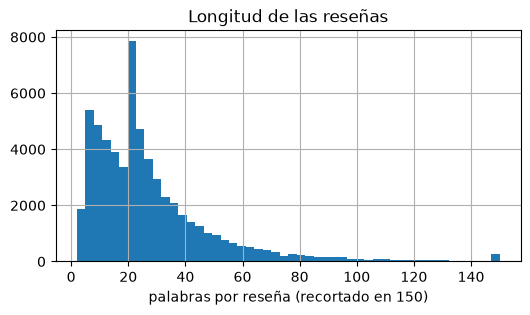

In [5]:
longitudes = pd.Series([len(t.split()) for t in X_train_txt])
print(longitudes.describe().round(1).to_string())
longitudes.clip(upper=150).hist(bins=50, figsize=(6, 3))
plt.xlabel("palabras por reseña (recortado en 150)")
plt.title("Longitud de las reseñas")
plt.show()

Las reseñas son cortas: la mayoría tiene menos de 50 palabras. Lo tendremos en cuenta al fijar la longitud de las secuencias.

<a id="vectorizacion-de-texto-con-keras"></a>
<h2 style="color: #007ACC;">Vectorización de texto con Keras</h2>

Las redes neuronales reciben **tensores de enteros**, así que hay que convertir cada texto en una secuencia de índices del vocabulario. La capa `TextVectorization` de Keras hace todo el proceso:

1. **Estandariza** el texto (minúsculas, sin puntuación). Definimos nuestra propia función para eliminar también los signos de apertura del español (`¡`, `¿`).
2. **Tokeniza** separando por espacios.
3. Construye el **vocabulario** con `adapt()` sobre el conjunto de entrenamiento, ordenado por frecuencia y limitado a `max_tokens`.
4. Convierte cada token en su índice. El índice 0 se reserva para el **relleno** (*padding*) y el 1 para las palabras **fuera del vocabulario** (`[UNK]`).
5. Rellena o recorta todas las secuencias a la misma longitud `output_sequence_length`, para poder agruparlas en lotes.

In [6]:
def estandarizar(texto):
    """Minúsculas y eliminación de puntuación, incluidos los signos de apertura del español."""
    texto = tf.strings.lower(texto)
    return tf.strings.regex_replace(texto, r"[¡¿«»“”\"#$%&()*+,\-./:;<=>?@\[\\\]^_`{|}~!']", " ")


MAX_TOKENS = 20_000
LONGITUD = 100

vectorizador = layers.TextVectorization(max_tokens=MAX_TOKENS, output_sequence_length=LONGITUD,
                                        standardize=estandarizar)
vectorizador.adapt(X_train_txt)  # el vocabulario se aprende SOLO con entrenamiento

vocab = [str(w) for w in vectorizador.get_vocabulary()]
print("Primeros términos del vocabulario:", vocab[:20])
print(f"Tamaño del vocabulario: {len(vocab)}")

Primeros términos del vocabulario: ['', '[UNK]', 'de', 'y', 'que', 'la', 'el', 'no', 'es', 'en', 'lo', 'se', 'muy', 'para', 'a', 'un', 'me', 'con', 'pero', 'los']
Tamaño del vocabulario: 20000


In [7]:
ejemplo = "¡Excelente producto! Llegó rápido, aunque la caja estaba un poco dañada."
secuencia = vectorizador([ejemplo])[0].numpy()
print(secuencia[:20])
print([vocab[i] for i in secuencia[:15]])

[ 287   31   84  126   66    5  111  154   15   39 2230    0    0    0
    0    0    0    0    0    0]
['excelente', 'producto', 'llegó', 'rápido', 'aunque', 'la', 'caja', 'estaba', 'un', 'poco', 'dañada', '', '', '', '']


In [8]:
X_train = vectorizador(np.array(X_train_txt)).numpy()
X_val = vectorizador(np.array(X_val_txt)).numpy()
X_test = vectorizador(np.array(X_test_txt)).numpy()

print("Forma de X_train:", X_train.shape)
print(f"Tokens fuera del vocabulario en validación: {(X_val == 1).sum() / (X_val > 0).sum():.1%}")
print(f"Reseñas de entrenamiento recortadas (más de {LONGITUD} tokens): {(longitudes > LONGITUD).mean():.1%}")

Forma de X_train: (60000, 100)
Tokens fuera del vocabulario en validación: 1.7%
Reseñas de entrenamiento recortadas (más de 100 tokens): 1.8%


<a id="la-capa-embedding"></a>
<h2 style="color: #007ACC;">La capa Embedding</h2>

La capa `Embedding(input_dim, output_dim)` contiene la matriz $E$ de tamaño $|V| \times d$, inicializada al azar. Recibe un tensor de índices de forma `(lote, longitud)` y devuelve un tensor de vectores de forma `(lote, longitud, d)`.

Con `mask_zero=True`, la capa genera además una **máscara** que marca qué posiciones son relleno (índice 0). Las capas siguientes que la soportan (como `GlobalAveragePooling1D` o las recurrentes) **ignoran** esas posiciones. Sin la máscara, el promedio de una reseña corta estaría dominado por los ceros del relleno.

In [9]:
capa = layers.Embedding(input_dim=MAX_TOKENS, output_dim=8, mask_zero=True)
salida = capa(X_train[:2])
print("Entrada:", X_train[:2].shape, "-> salida:", tuple(salida.shape))
corta = vectorizador(["Muy buen producto, lo recomiendo"])
print("Máscara de una reseña corta (primeras 15 posiciones):")
print(capa.compute_mask(corta)[0, :15].numpy().astype(int))
print(f"Parámetros de la capa: {MAX_TOKENS} x 8 = {capa.count_params():,}")

Entrada: (2, 100) -> salida: (2, 100, 8)
Máscara de una reseña corta (primeras 15 posiciones):
[1 1 1 1 1 0 0 0 0 0 0 0 0 0 0]
Parámetros de la capa: 20000 x 8 = 160,000


<a id="un-clasificador-con-embeddings"></a>
<h2 style="color: #007ACC;">Un clasificador con embeddings</h2>

El clasificador más simple con embeddings (similar a **fastText**, Joulin et al., 2017) promedia los vectores de las palabras de la reseña y pasa el resultado por capas densas:

```text
índices (100) → Embedding (100 × 16) → promedio (16) → Dense(16, relu) → Dense(1, sigmoide)
```

El promedio de embeddings es una "bolsa de palabras densa": todavía ignora el orden (eso lo resolveremos con redes recurrentes en el cuaderno 13), pero las palabras ya comparten información a través de sus vectores. Los embeddings se entrenan **junto con el resto de la red**, para la tarea de clasificar sentimiento.

In [10]:
def graficar_historial(historial, titulo="Curvas de entrenamiento"):
    h = historial.history
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    for ax, metrica in zip(axes, ["loss", "accuracy"]):
        ax.plot(h[metrica], marker="o", label="entrenamiento")
        ax.plot(h["val_" + metrica], marker="o", label="validación")
        ax.set_xlabel("época")
        ax.set_title(metrica)
        ax.legend()
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()


def modelo_promedio(dim=16):
    return keras.Sequential([
        keras.Input(shape=(LONGITUD,), dtype="int64"),
        layers.Embedding(MAX_TOKENS, dim, mask_zero=True, name="embedding"),
        layers.GlobalAveragePooling1D(),
        layers.Dense(16, activation="relu"),
        layers.Dense(1, activation="sigmoid"),
    ])


modelo = modelo_promedio()
modelo.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
modelo.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 100, 16)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 16)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 320,289 (1.22 MB)

 Trainable params: 320,289 (1.22 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10


235/235 - 1s - 3ms/step - accuracy: 0.7971 - loss: 0.5180 - val_accuracy: 0.8503 - val_loss: 0.3731


Epoch 2/10


235/235 - 0s - 2ms/step - accuracy: 0.8723 - loss: 0.3197 - val_accuracy: 0.8687 - val_loss: 0.3090


Epoch 3/10


...

Epoch 5/10


235/235 - 0s - 2ms/step - accuracy: 0.9151 - loss: 0.2280 - val_accuracy: 0.8785 - val_loss: 0.2922


Epoch 6/10


235/235 - 0s - 2ms/step - accuracy: 0.9218 - loss: 0.2134 - val_accuracy: 0.8758 - val_loss: 0.2982


Entrenado en 3 s


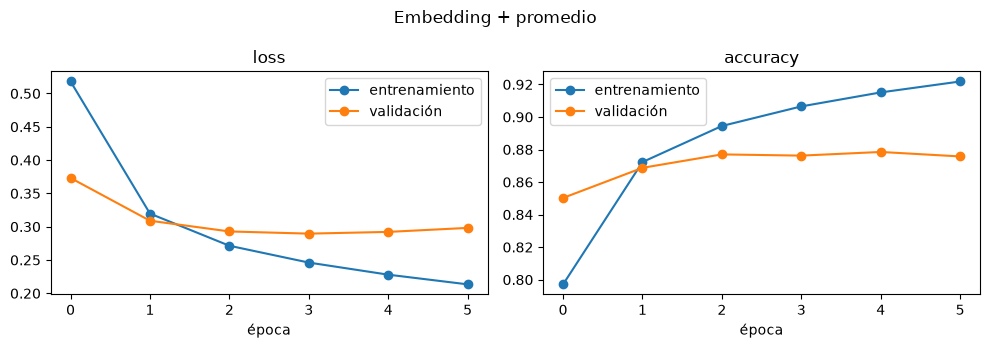

In [11]:
parada = keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)
inicio = time.perf_counter()
historial = modelo.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=10, batch_size=256,
                       callbacks=[parada], verbose=2)
print(f"Entrenado en {time.perf_counter() - inicio:.0f} s")
graficar_historial(historial, "Embedding + promedio")

Comparemos en el conjunto de **prueba** con la línea base del módulo 1: TF-IDF + regresión logística.

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

base = TfidfVectorizer(min_df=2, ngram_range=(1, 2)).fit(X_train_txt)
lr = LogisticRegression(max_iter=2000).fit(base.transform(X_train_txt), y_train)

resultados = pd.Series({
    "TF-IDF (1-2 gramas) + regresión logística": accuracy_score(y_test, lr.predict(base.transform(X_test_txt))),
    "Embedding (d=16) + promedio": modelo.evaluate(X_test, y_test, verbose=0)[1],
}, name="exactitud en prueba")
resultados.round(4).to_frame()

,exactitud en prueba
TF-IDF (1-2 gramas) + regresión logística,0.9028
Embedding (d=16) + promedio,0.8873


La línea base TF-IDF con bigramas es incluso un poco mejor. Con 60 000 ejemplos etiquetados y textos cortos, una buena bolsa de N-gramas es una línea base difícil de superar; las ventajas de los embeddings aparecen sobre todo cuando:

- hay **pocos datos etiquetados** y podemos usar embeddings **preentrenados** en mucho texto sin etiquetar (cuaderno 12),
- el modelo necesita el **orden** de las palabras (redes recurrentes, cuaderno 13),
- queremos representaciones reutilizables entre tareas.

Además, el modelo de embeddings tiene muchos menos parámetros que el modelo TF-IDF con bigramas, y sus representaciones son densas.

In [13]:
for frase in ["Muy buena calidad, lo recomiendo", "No funciona, una pérdida de dinero",
              "No está mal, pero esperaba más", "El envío tardó mucho pero el producto es genial"]:
    p = modelo.predict(vectorizador([frase]), verbose=0)[0, 0]
    print(f"{frase:<52} P(positiva) = {p:.3f}")

Muy buena calidad, lo recomiendo                     P(positiva) = 0.998
No funciona, una pérdida de dinero                   P(positiva) = 0.001
No está mal, pero esperaba más                       P(positiva) = 0.003
El envío tardó mucho pero el producto es genial      P(positiva) = 0.992


La reseña con contraste (*"tardó mucho pero ... es genial"*) se clasifica bien porque *genial* tiene mucho peso. *"No está mal, pero esperaba más"* se considera claramente negativa: el promedio ve *mal* y *no* (que en este corpus aparece sobre todo en reseñas negativas), sin entender que *no está mal* es una valoración tibia.

<a id="visualizacion-de-los-embeddings-aprendidos"></a>
<h2 style="color: #007ACC;">Visualización de los embeddings aprendidos</h2>

Los embeddings aprendidos son la matriz de pesos de la primera capa. ¿Qué palabras quedaron cerca entre sí? Usamos la similitud coseno, como en el cuaderno 05.

In [14]:
E = modelo.get_layer("embedding").get_weights()[0]
E_norm = E / (np.linalg.norm(E, axis=1, keepdims=True) + 1e-9)
indice = {w: i for i, w in enumerate(vocab)}


def vecinos(palabra, k=8):
    sims = E_norm @ E_norm[indice[palabra]]
    return ", ".join(vocab[i] for i in np.argsort(-sims)[1:k + 1])


for palabra in ["excelente", "horrible", "recomiendo", "devolver", "rápido", "batería"]:
    print(f"{palabra:<11} -> {vecinos(palabra)}")

excelente   -> perfecto, previsto, encantado, duda, contento, única, perfecta, fenomenal
horrible    -> devuelvo, devolver, decepcionada, devolución, descosido, decepcionado, incómodo, descontenta
recomiendo  -> va, que, un, funciona, mi, mucho, fecha, redmi
devolver    -> mala, devolverlo, decepción, horrible, devolví, decepcionado, decepcionada, estafa
rápido      -> antes, efectivo, ocupan, ligereza, nevera, regalito, permiten, siempre
batería     -> cost, tendera, pelusa, falle, collar, encargada, haberme, grasas


Los vecinos reflejan la **tarea** con la que se entrenaron los embeddings: *excelente* queda cerca de otras palabras positivas y *horrible* de otras negativas (*devolver*, *decepcionado*), sin importar su categoría gramatical ni su significado preciso.

Las palabras neutras para el sentimiento (*batería*, *rápido*) tienen vecinos poco interpretables, porque la red no necesitó organizarlas. El caso de *recomiendo* es revelador: aunque parece positiva, aparece tanto en *"lo recomiendo"* como en *"no lo recomiendo"*, así que por sí sola no indica la polaridad y su vector queda en una zona "neutra", junto a palabras funcionales como *que* o *un*.

Como la última capa separa clases, podemos proyectar cada palabra sobre la dirección que mejor separa positivo de negativo. Usamos como aproximación la diferencia entre los promedios de algunas palabras claramente positivas y negativas:

In [15]:
positivas = ["excelente", "perfecto", "genial", "encanta", "ideal"]
negativas = ["horrible", "pésimo", "roto", "devolver", "decepcionado"]
direccion = E[[indice[w] for w in positivas]].mean(axis=0) - E[[indice[w] for w in negativas]].mean(axis=0)
direccion /= np.linalg.norm(direccion)

# Solo palabras frecuentes (los primeros 3000 índices del vocabulario)
puntajes = E[2:3000] @ direccion
orden = np.argsort(puntajes)
print("Más negativas:", ", ".join(vocab[2 + i] for i in orden[:15]))
print("Más positivas:", ", ".join(vocab[2 + i] for i in orden[::-1][:15]))

Más negativas: mala, devuelto, decepción, decepcionado, decepcionada, devolver, devolución, imposible, devolví, devolverlo, fatal, devuelvo, tirado, estafa, roto
Más positivas: perfectamente, perfecto, encantado, encantada, encanta, perfecta, genial, ideal, excelente, contento, única, sorprendido, perfección, satisfecho, acierto


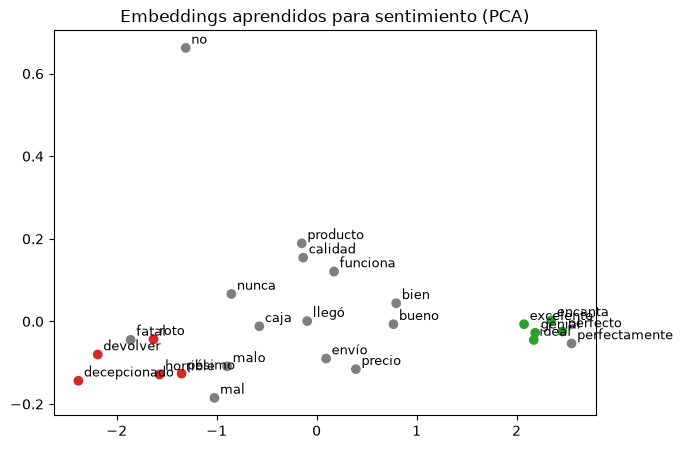

In [16]:
from sklearn.decomposition import PCA

palabras = positivas + negativas + ["bueno", "malo", "bien", "mal", "calidad", "precio", "envío", "producto",
                                    "caja", "llegó", "funciona", "no", "nunca", "perfectamente", "fatal"]
palabras = [w for w in palabras if w in indice]
P = PCA(n_components=2, random_state=SEED).fit_transform(E[[indice[w] for w in palabras]])

plt.figure(figsize=(7, 5))
colores = ["tab:green" if w in positivas else "tab:red" if w in negativas else "tab:gray" for w in palabras]
plt.scatter(P[:, 0], P[:, 1], c=colores)
for w, (x, y) in zip(palabras, P):
    plt.annotate(w, (x, y), xytext=(4, 3), textcoords="offset points", fontsize=9)
plt.title("Embeddings aprendidos para sentimiento (PCA)")
plt.show()

<a id="embeddings-en-dos-dimensiones"></a>
<h2 style="color: #007ACC;">Embeddings en dos dimensiones</h2>

Para ver los embeddings **sin** reducción de dimensión, entrenemos el mismo modelo con $d = 2$. Cada palabra es entonces un punto en el plano. ¿Cuánto se pierde con solo dos dimensiones?

In [17]:
resumen = {}
modelos_d = {}
for dim in [2, 16, 64]:
    keras.utils.set_random_seed(SEED)
    m = modelo_promedio(dim)
    m.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    m.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=10, batch_size=256,
          callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)],
          verbose=0)
    modelos_d[dim] = m
    resumen[dim] = {"parámetros del embedding": MAX_TOKENS * dim, "exactitud en validación": m.evaluate(X_val, y_val, verbose=0)[1]}
pd.DataFrame(resumen).T.round(4)

,parámetros del embedding,exactitud en validación
2,40000.0,0.8758
16,320000.0,0.8783
64,1280000.0,0.8788


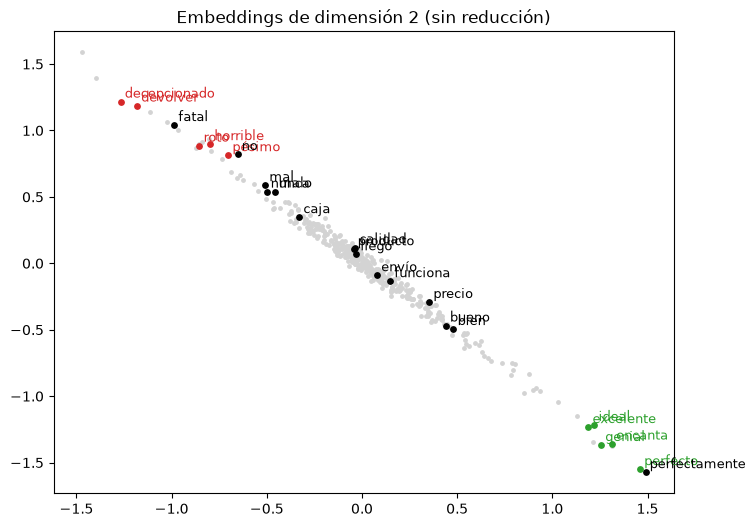

In [18]:
E2 = modelos_d[2].get_layer("embedding").get_weights()[0]
frecuentes = np.arange(2, 400)  # las palabras más frecuentes

plt.figure(figsize=(8, 6))
plt.scatter(E2[frecuentes, 0], E2[frecuentes, 1], s=6, c="lightgray")
for w in palabras:
    x, y = E2[indice[w]]
    color = "tab:green" if w in positivas else "tab:red" if w in negativas else "black"
    plt.scatter(x, y, c=color, s=15)
    plt.annotate(w, (x, y), xytext=(3, 3), textcoords="offset points", fontsize=9, color=color)
plt.title("Embeddings de dimensión 2 (sin reducción)")
plt.show()

Para una tarea binaria, dos dimensiones bastan para obtener casi la misma exactitud (la diferencia con $d = 64$ es de unas décimas de punto): el modelo esencialmente necesita **un eje** de sentimiento. En el plano se ve cómo las palabras positivas y negativas se alinean a lo largo de una dirección, y las palabras neutras se acumulan cerca del centro.

**Conclusión:** los embeddings aprendidos para una tarea capturan solo lo que la tarea necesita. Para obtener representaciones de **significado general**, reutilizables en muchas tareas, hay que entrenarlas con un objetivo que no dependa de etiquetas: predecir las palabras de alrededor. Eso es **Word2Vec**, el tema del siguiente cuaderno.

<a id="referencias"></a>
<h2 style="color: #007ACC;">Referencias</h2>

- Jurafsky, D. & Martin, J. H. *Speech and Language Processing* (3.ª ed. borrador). [web.stanford.edu/~jurafsky/slp3](https://web.stanford.edu/~jurafsky/slp3/)
- Tunstall, L., von Werra, L. & Wolf, T. (2022). *Natural Language Processing with Transformers*. O'Reilly Media.
- Chollet, F. (2021). *Deep Learning with Python* (2.ª ed.), capítulo 11. Manning.
- Joulin, A., Grave, E., Bojanowski, P. & Mikolov, T. (2017). Bag of Tricks for Efficient Text Classification. *EACL*.
- Keung, P., Lu, Y., Szarvas, G. & Smith, N. A. (2020). The Multilingual Amazon Reviews Corpus. *EMNLP*.